In [1]:
!pip install -q ijson         
import os, gc, json, math, time, glob, random, zipfile, csv, warnings
warnings.filterwarnings("ignore")
 
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, PreTrainedTokenizerFast
 
try:
    import ijson
except ImportError:
    ijson = None
    print("ijson not installed -> falling back to json.load (needs lots of RAM for big files)")
 
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = None

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 3.6 MB/s eta 0:00:00a 0:00:01


In [2]:
QUICK_TEST = False   # True = small end-to-end check (~15 min). Set False for the real run.
 
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
 
# ---- model ----
# GQA shrinks K/V projections, so 8 layers = ~47.9M (< 50M limit).
# 9 layers = ~50.66M, close to Model 2 (~51.04M) -> fair comparison by parameter count.
N_LAYER, N_HEAD, D_MODEL, BLOCK_SIZE = 9, 8, 512, 1024
N_KV_HEAD = 2         # GQA: 8 query heads share 2 key/value heads
WINDOW_SIZE = 256     # sliding-window attention span
FFN_DIM = 1376        # SwiGLU hidden ~ 8/3 * d_model (rounded to a multiple of 16)
assert N_HEAD % N_KV_HEAD == 0
 
# ---- training (your values) ----
MICRO_BATCH_SIZE, GRAD_ACCUM_STEPS = 4, 8
LEARNING_RATE, MIN_LR, WEIGHT_DECAY, WARMUP_RATIO = 3e-4, 3e-5, 0.1, 0.03
VAL_EVERY, EVAL_BATCHES, LOG_EVERY = 500, 50, 20
TIME_BUDGET_HOURS = 11.0          # stop + save before Kaggle's 12h limit
 
# ---- data mix: training-token budget per source (YOUR experiment knob) ----
TRAIN_BUDGETS = {
    "train_acts.json":           50_000_000,
    "train_high_courts.json":    50_000_000,
    "train_supreme_court.json":  50_000_000,
    "train_tribunals.json":      50_000_000,
}
KEEP_PROB = 0.3        # while streaming a file, keep each document with this probability
                       # (so we don't only take the first documents of the file)
VAL_FRAC = 0.05        # fraction of kept documents that go to validation
MAX_VAL_TOKENS = 5_000_000
 
# ---- generation (your sampling values) ----
TEMPERATURE, TOP_K, TOP_P = 0.8, 50, 0.95
TARGET_WORDS = 128     # competition needs exactly 128 WORDS
MAX_NEW_TOKENS = 1024  # upper limit; generation stops early once 128 words exist
GEN_BATCH = 16
TEST_FILE_OVERRIDE = "/tmp/cs781_data/Phase_1_Pretraining/Test/test.json"
 
OUTPUT_DIR = "/kaggle/working/phase1_model3_gqa_swa"
 
if QUICK_TEST:
    TRAIN_BUDGETS = {k: 1_000_000 for k in TRAIN_BUDGETS}
    MAX_VAL_TOKENS, VAL_EVERY, EVAL_BATCHES, LOG_EVERY = 200_000, 50, 10, 10
    OUTPUT_DIR = "/kaggle/working/phase1_model3_quick"
 
os.makedirs(OUTPUT_DIR, exist_ok=True)

Device: cuda Tesla T4


In [3]:
from huggingface_hub import snapshot_download
DATA_DIR = snapshot_download(
    "Exploration-Lab/CS-781-Capstone", repo_type="dataset", token=HF_TOKEN,
    allow_patterns=["*Phase_1*", "*Phase1*"],
    local_dir="/tmp/cs781_data",          # /tmp avoids the 20GB /kaggle/working limit
)
all_json_files = (glob.glob("/kaggle/input/**/*.json", recursive=True)
                  + glob.glob(f"{DATA_DIR}/**/*.json", recursive=True))
 
def find_file(name):
    m = [f for f in all_json_files if os.path.basename(f).lower() == name.lower()]
    return m[0] if m else None
 
TRAIN_FILES = {name: find_file(name) for name in TRAIN_BUDGETS}
for name, path in TRAIN_FILES.items():
    print(f"{name:28s} -> {path}")
TRAIN_FILES = {k: v for k, v in TRAIN_FILES.items() if v is not None}
if not TRAIN_FILES:
    raise FileNotFoundError("No Phase-1 training files found. Attach the dataset to the notebook.")
 
def norm(s):
    return s.lower().replace(" ", "").replace("_", "").replace("-", "")
 
if TEST_FILE_OVERRIDE:
    TEST_FILE = TEST_FILE_OVERRIDE
else:
    cands = [f for f in all_json_files if "phase1test" in norm(os.path.basename(f))]
    if not cands:
        cands = [f for f in all_json_files if "test" in os.path.basename(f).lower()
                 and "phase" in norm(f) and "1" in os.path.basename(f)]
    TEST_FILE = cands[0] if cands else None
print("\nTEST FILE ->", TEST_FILE, "   <-- verify this is the Phase 1 test file!")
assert TEST_FILE and os.path.exists(TEST_FILE), "Phase 1 test file not found - fix TEST_FILE_OVERRIDE"

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

train_acts.json              -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_acts.json
train_high_courts.json       -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_high_courts.json
train_supreme_court.json     -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_supreme_court.json
train_tribunals.json         -> /tmp/cs781_data/Phase_1_Pretraining/Train/train_tribunals.json

TEST FILE -> /tmp/cs781_data/Phase_1_Pretraining/Test/test.json    <-- verify this is the Phase 1 test file!


In [4]:
tokenizer = None
tok_jsons = [f for f in glob.glob("/kaggle/input/**/tokenizer*.json", recursive=True)
             if "config" not in os.path.basename(f)]   # also matches "tokenizer (1).json"
if tok_jsons:
    try:
        tokenizer = PreTrainedTokenizerFast(tokenizer_file=tok_jsons[0])
        print("Loaded tokenizer:", tok_jsons[0])
    except Exception as e:
        print("Could not load tokenizer.json:", e)
if tokenizer is None:
    tokenizer = AutoTokenizer.from_pretrained("gpt2", token=HF_TOKEN)
    print("Using GPT-2 BPE tokenizer")
 
if tokenizer.eos_token is None:
    tokenizer.add_special_tokens({"eos_token": "<|endoftext|>"})
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.model_max_length = int(1e9)   # we chunk ourselves
 
VOCAB_SIZE = len(tokenizer)
EOS_TOKEN_ID = tokenizer.eos_token_id
TOKEN_DTYPE = np.uint16 if VOCAB_SIZE < 65535 else np.uint32
print("Vocab size:", VOCAB_SIZE, "| EOS:", EOS_TOKEN_ID, "  (legal BPE -> EOS 0, GPT-2 -> EOS 50256)")

Loaded tokenizer: /kaggle/input/datasets/kavyajain123987/phase1/tokenizer (1).json
Vocab size: 50257 | EOS: 0   (legal BPE -> EOS 0, GPT-2 -> EOS 50256)


In [5]:
TRAIN_BIN = os.path.join(OUTPUT_DIR, "train.bin")
VAL_BIN = os.path.join(OUTPUT_DIR, "val.bin")
 
def iter_texts(path):
    """Yield one document text at a time. Handles [{"text":..}, ...] and {"1": {"text":..}, ...}."""
    def text_of(rec):
        if isinstance(rec, dict):
            for key in ("text", "content", "document", "body"):
                if isinstance(rec.get(key), str):
                    return rec[key]
        return rec if isinstance(rec, str) else None
 
    if ijson is not None:
        with open(path, "rb") as f:
            first = f.read(1)
            while first.isspace():
                first = f.read(1)
            f.seek(0)
            it = ijson.items(f, "item") if first == b"[" else (v for _, v in ijson.kvitems(f, ""))
            for rec in it:
                t = text_of(rec)
                if t: yield t
    else:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for rec in (data if isinstance(data, list) else data.values()):
            t = text_of(rec)
            if t: yield t
        del data; gc.collect()
 
def build_token_files():
    if os.path.exists(TRAIN_BIN) and os.path.exists(VAL_BIN):
        print("Token files exist, skipping build."); return
    rng = random.Random(SEED)
    total_budget = sum(TRAIN_BUDGETS[k] for k in TRAIN_FILES)
    train_chunks, val_chunks = [], []
    for name, path in TRAIN_FILES.items():
        budget = TRAIN_BUDGETS[name]
        val_budget = int(MAX_VAL_TOKENS * budget / total_budget)
        n_tr = n_va = 0
        batch = []
 
        def flush(batch):
            nonlocal n_tr, n_va
            for ids in tokenizer(batch, add_special_tokens=False)["input_ids"]:
                arr = np.array(ids + [EOS_TOKEN_ID], dtype=TOKEN_DTYPE)   # EOS after EVERY document
                if rng.random() < VAL_FRAC:
                    if n_va < val_budget:
                        val_chunks.append(arr); n_va += len(arr)
                elif n_tr < budget:
                    train_chunks.append(arr); n_tr += len(arr)
 
        t0 = time.time()
        for text in iter_texts(path):
            if rng.random() > KEEP_PROB:
                continue
            batch.append(text)
            if len(batch) == 256:
                flush(batch); batch = []
                if n_tr >= budget and n_va >= val_budget:
                    break
        if batch:
            flush(batch)
        print(f"{name}: train {n_tr:,} | val {n_va:,} tokens | {time.time() - t0:.0f}s")
        if n_tr < budget:
            print(f"   (file ran out before budget - raise KEEP_PROB to get more from {name})")
    rng.shuffle(train_chunks)   # mix sources at document level
    np.concatenate(train_chunks).tofile(TRAIN_BIN)
    np.concatenate(val_chunks).tofile(VAL_BIN)
    del train_chunks, val_chunks; gc.collect()
 
build_token_files()
train_data = np.memmap(TRAIN_BIN, dtype=TOKEN_DTYPE, mode="r")
val_data = np.memmap(VAL_BIN, dtype=TOKEN_DTYPE, mode="r")
print(f"Train tokens: {len(train_data):,} | Val tokens: {len(val_data):,}")

train_acts.json: train 41,194,167 | val 1,329,916 tokens | 58s
   (file ran out before budget - raise KEEP_PROB to get more from train_acts.json)
train_high_courts.json: train 50,000,654 | val 1,250,087 tokens | 67s
train_supreme_court.json: train 50,004,806 | val 1,251,815 tokens | 71s
train_tribunals.json: train 50,000,155 | val 1,250,054 tokens | 65s
Train tokens: 191,199,782 | Val tokens: 5,081,872


In [6]:
B, T = MICRO_BATCH_SIZE, BLOCK_SIZE
 
def to_dev(x, y):
    if DEVICE.type == "cuda":
        return x.pin_memory().to(DEVICE, non_blocking=True), y.pin_memory().to(DEVICE, non_blocking=True)
    return x.to(DEVICE), y.to(DEVICE)
 
def make_xy(data, starts):
    x = torch.from_numpy(np.stack([data[i:i + T].astype(np.int64) for i in starts]))
    y = torch.from_numpy(np.stack([data[i + 1:i + 1 + T].astype(np.int64) for i in starts]))
    return to_dev(x, y)
 
def get_train_batch():
    return make_xy(train_data, np.random.randint(0, len(train_data) - T - 1, size=B))
 
# evenly spaced over the WHOLE val set -> every source is represented
VAL_STARTS = np.linspace(0, len(val_data) - T - 2, EVAL_BATCHES * B).astype(int).tolist()
assert len(VAL_STARTS) > 0, "Validation set too small for one block - increase MAX_VAL_TOKENS"

In [7]:
class RMSNorm(nn.Module):
    """x / sqrt(mean(x^2) + eps) * weight  (no mean subtraction, unlike LayerNorm)"""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps
 
    def forward(self, x):
        rms = torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (x * rms) * self.weight
 
 
class RotaryEmbedding(nn.Module):
    """RoPE: rotate q and k by position-dependent angles (relative position info)."""
    def __init__(self, dim, max_seq_len, theta=10000.0):
        super().__init__()
        self.dim = dim
        self.max_seq_len = max_seq_len
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        self.register_buffer("inv_freq", inv_freq, persistent=False)
        self._build_cache(max_seq_len)
 
    def _build_cache(self, seq_len):
        positions = torch.arange(seq_len, device=self.inv_freq.device, dtype=self.inv_freq.dtype)
        freqs = torch.outer(positions, self.inv_freq)
        emb = torch.cat([freqs, freqs], dim=-1)
        self.register_buffer("cos_cached", emb.cos()[None, :, :], persistent=False)
        self.register_buffer("sin_cached", emb.sin()[None, :, :], persistent=False)
 
    def forward(self, q, k):
        seq_len = q.size(-2)
        if seq_len > self.cos_cached.size(1):
            self._build_cache(seq_len)
        cos = self.cos_cached[:, :seq_len, :].to(q.dtype)
        sin = self.sin_cached[:, :seq_len, :].to(q.dtype)
        return apply_rotary(q, cos, sin), apply_rotary(k, cos, sin)
 
 
def rotate_half(x):
    half = x.shape[-1] // 2
    x1, x2 = x[..., :half], x[..., half:]
    return torch.cat([-x2, x1], dim=-1)
 
 
def apply_rotary(x, cos, sin):
    return x * cos + rotate_half(x) * sin
 
 
class SwiGLU(nn.Module):
    """down( SiLU(gate(x)) * up(x) ), no bias"""
    def __init__(self, d_model, ffn_dim):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, ffn_dim, bias=False)
        self.up_proj = nn.Linear(d_model, ffn_dim, bias=False)
        self.down_proj = nn.Linear(ffn_dim, d_model, bias=False)
 
    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))
 
 
class GQASlidingWindowAttention(nn.Module):
    """
    GQA: n_heads query heads share n_kv_heads key/value heads (8 Q -> 2 KV: each KV head serves 4 Q heads).
    Sliding window: token i attends only to tokens j with 0 <= i - j < window_size (causal + local).
    """
    def __init__(self, d_model, n_heads, n_kv_heads, max_seq_len, window_size):
        super().__init__()
        assert d_model % n_heads == 0
        assert n_heads % n_kv_heads == 0
        self.d_model = d_model
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.head_dim = d_model // n_heads
        self.window_size = window_size
        self.q_proj = nn.Linear(d_model, n_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.rope = RotaryEmbedding(self.head_dim, max_seq_len)
        # mask[q, k] = True -> q may attend to k   (k <= q  AND  q - k < window)
        positions = torch.arange(max_seq_len)
        distance = positions[:, None] - positions[None, :]
        self.register_buffer("window_mask", (distance >= 0) & (distance < window_size), persistent=False)
 
    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)     # [B, 8, T, D]
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)  # [B, 2, T, D]
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)  # [B, 2, T, D]
        q, k = self.rope(q, k)
        repeat_factor = self.n_heads // self.n_kv_heads
        k = k.repeat_interleave(repeat_factor, dim=1)                                  # [B, 8, T, D]
        v = v.repeat_interleave(repeat_factor, dim=1)
        mask = self.window_mask[:T, :T]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=0.0)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(y)
 
 
class LLaMABlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, ffn_dim, max_seq_len, window_size):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attention = GQASlidingWindowAttention(d_model=d_model, n_heads=n_heads, n_kv_heads=n_kv_heads,
                                                   max_seq_len=max_seq_len, window_size=window_size)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU(d_model, ffn_dim)
 
    def forward(self, x):
        x = x + self.attention(self.attn_norm(x))   # pre-norm
        x = x + self.ffn(self.ffn_norm(x))
        return x
 
 
class LLaMALanguageModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.token_embedding = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList([
            LLaMABlock(d_model=cfg.d_model, n_heads=cfg.n_heads, n_kv_heads=cfg.n_kv_heads, ffn_dim=cfg.ffn_dim,
                       max_seq_len=cfg.max_seq_len, window_size=cfg.window_size)
            for _ in range(cfg.n_layers)])
        self.final_norm = RMSNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight      # weight tying
        self.apply(self._init_weights)
 
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
 
    def forward(self, idx, targets=None):
        x = self.token_embedding(idx)          # no position embedding: RoPE handles position
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

In [8]:
from types import SimpleNamespace
MODEL_CFG = dict(vocab_size=VOCAB_SIZE, d_model=D_MODEL, n_layers=N_LAYER, n_heads=N_HEAD,
                 n_kv_heads=N_KV_HEAD, ffn_dim=FFN_DIM, max_seq_len=BLOCK_SIZE, window_size=WINDOW_SIZE)
model = LLaMALanguageModel(SimpleNamespace(**MODEL_CFG)).to(DEVICE)
num_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {num_params:,} ({num_params / 1e6:.2f}M)")
if not (50_000_000 <= num_params <= 300_000_000):
    raise ValueError(f"{num_params / 1e6:.2f}M params - Phase 1 requires 50M-300M "
                     "(a smaller tokenizer vocab shrinks the embedding table)")

Parameters: 50,661,376 (50.66M)


In [9]:
decay, no_decay = [], []
for name, p in model.named_parameters():
    if p.requires_grad:
        (decay if p.dim() >= 2 and "wpe" not in name else no_decay).append(p)
optimizer = torch.optim.AdamW(
    [{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
    lr=LEARNING_RATE, betas=(0.9, 0.95), eps=1e-8)
 
tokens_per_step = MICRO_BATCH_SIZE * BLOCK_SIZE * GRAD_ACCUM_STEPS
TOTAL_STEPS = max(1, len(train_data) // tokens_per_step)     # ~1 pass over the training tokens
WARMUP_STEPS = max(1, int(TOTAL_STEPS * WARMUP_RATIO))
print(f"Tokens/step {tokens_per_step:,} | total steps {TOTAL_STEPS:,} | warmup {WARMUP_STEPS}")
 
def get_lr(step):
    if step < WARMUP_STEPS:
        return LEARNING_RATE * (step + 1) / WARMUP_STEPS
    progress = min(max((step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS), 0.0), 1.0)
    return MIN_LR + (LEARNING_RATE - MIN_LR) * 0.5 * (1 + math.cos(math.pi * progress))
 
USE_AMP = DEVICE.type == "cuda"
USE_BF16 = USE_AMP and torch.cuda.get_device_capability()[0] >= 8   # T4 -> fp16
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and not USE_BF16)
 
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP)
 
@torch.no_grad()
def estimate_loss():
    model.eval()
    losses = []
    for s in range(0, len(VAL_STARTS), B):
        x, y = make_xy(val_data, VAL_STARTS[s:s + B])
        with autocast():
            _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

Tokens/step 32,768 | total steps 5,834 | warmup 175


In [10]:
LAST_CKPT = os.path.join(OUTPUT_DIR, "last.pt")    # model + optimizer (for resuming)
BEST_CKPT = os.path.join(OUTPUT_DIR, "best.pt")    # model only (best val loss)
LOG_CSV = os.path.join(OUTPUT_DIR, "log.csv")
 
global_step, best_val_loss = 0, float("inf")
if os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=DEVICE)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scaler.load_state_dict(ck["scaler"])
    global_step, best_val_loss = ck["step"], ck["best_val_loss"]
    print(f"Resumed from step {global_step} (best val {best_val_loss:.4f})")
 
def save_last():
    torch.save({"step": global_step, "best_val_loss": best_val_loss, "model": model.state_dict(),
                "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                "config": MODEL_CFG}, LAST_CKPT)
 
def save_best():
    torch.save({"step": global_step, "val_loss": best_val_loss, "model": model.state_dict(),
                "config": MODEL_CFG}, BEST_CKPT)
 
def log_row(row):
    new = not os.path.exists(LOG_CSV)
    with open(LOG_CSV, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["step", "split", "loss", "lr", "tok_per_s"])
        if new: w.writeheader()
        w.writerow(row)

In [11]:
print("\n================ TRAINING ================")
model.train()
start_time = t_log = time.time()
running = 0.0
while global_step < TOTAL_STEPS:
    current_lr = get_lr(global_step)
    for g in optimizer.param_groups:
        g["lr"] = current_lr
    optimizer.zero_grad(set_to_none=True)
    step_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        x, y = get_train_batch()
        with autocast():
            _, loss = model(x, y)
            loss = loss / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        step_loss += loss.item()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer); scaler.update()
    global_step += 1
    running += step_loss
 
    if global_step % LOG_EVERY == 0:
        dt = time.time() - t_log; t_log = time.time()
        tps = LOG_EVERY * tokens_per_step / dt
        eta = (TOTAL_STEPS - global_step) * tokens_per_step / tps / 3600
        avg = running / LOG_EVERY; running = 0.0
        print(f"Step {global_step:5d}/{TOTAL_STEPS} | loss {avg:.4f} | lr {current_lr:.2e} "
              f"| {tps:,.0f} tok/s | ETA {eta:.2f}h")
        log_row({"step": global_step, "split": "train", "loss": avg, "lr": current_lr, "tok_per_s": tps})
 
    out_of_time = (time.time() - start_time) / 3600 > TIME_BUDGET_HOURS
    if global_step % VAL_EVERY == 0 or global_step == TOTAL_STEPS or out_of_time:
        val_loss = estimate_loss()
        print(f"  >> val loss {val_loss:.4f} | val ppl {math.exp(min(val_loss, 20)):.2f}")
        log_row({"step": global_step, "split": "val", "loss": val_loss, "lr": current_lr, "tok_per_s": ""})
        if val_loss < best_val_loss:
            best_val_loss = val_loss; save_best(); print("  >> best checkpoint saved")
        save_last()
    if out_of_time:
        print("Time budget reached. Checkpoint saved - re-run the notebook to resume."); break
 
if DEVICE.type == "cuda":
    PEAK_MEM_GB = torch.cuda.max_memory_allocated() / 1024**3
    print(f"Peak GPU memory: {PEAK_MEM_GB:.2f} GB")
print(f"Training time {(time.time() - start_time) / 3600:.2f}h | best val loss {best_val_loss:.4f} "
      f"(ppl {math.exp(min(best_val_loss, 20)):.2f})")


================ TRAINING ================
Step    20/5834 | loss 10.4373 | lr 3.43e-05 | 21,160 tok/s | ETA 2.50h
Step    40/5834 | loss 9.4242 | lr 6.86e-05 | 20,592 tok/s | ETA 2.56h
Step    60/5834 | loss 8.5882 | lr 1.03e-04 | 19,716 tok/s | ETA 2.67h
Step    80/5834 | loss 7.4970 | lr 1.37e-04 | 20,093 tok/s | ETA 2.61h
Step   100/5834 | loss 6.6911 | lr 1.71e-04 | 19,991 tok/s | ETA 2.61h
Step   120/5834 | loss 6.2778 | lr 2.06e-04 | 19,931 tok/s | ETA 2.61h
Step   140/5834 | loss 5.9561 | lr 2.40e-04 | 19,950 tok/s | ETA 2.60h
Step   160/5834 | loss 5.6788 | lr 2.74e-04 | 19,958 tok/s | ETA 2.59h
Step   180/5834 | loss 5.3670 | lr 3.00e-04 | 19,949 tok/s | ETA 2.58h
Step   200/5834 | loss 5.2192 | lr 3.00e-04 | 19,965 tok/s | ETA 2.57h
Step   220/5834 | loss 5.0019 | lr 3.00e-04 | 19,952 tok/s | ETA 2.56h
Step   240/5834 | loss 4.8896 | lr 3.00e-04 | 19,966 tok/s | ETA 2.55h
Step   260/5834 | loss 4.6938 | lr 3.00e-04 | 19,952 tok/s | ETA 2.54h
Step   280/5834 | loss 4.5755 | 

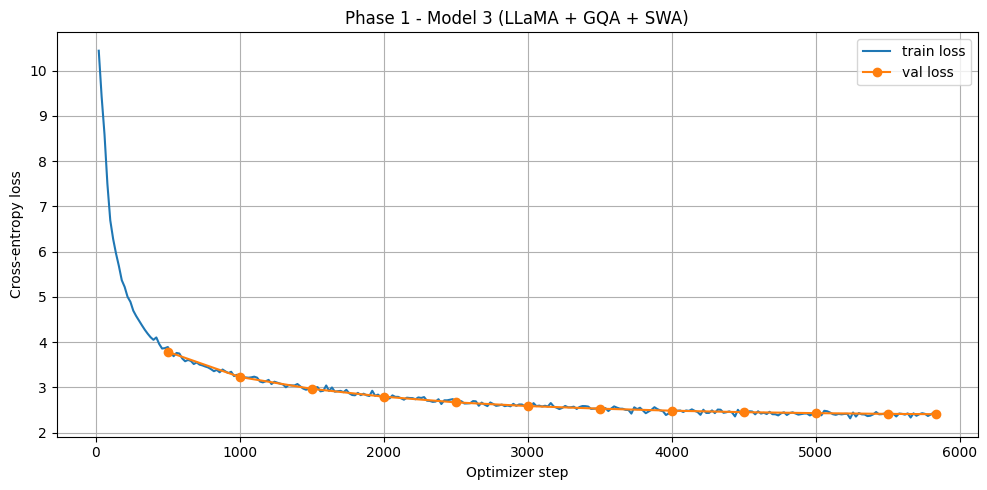

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(LOG_CSV)
plt.figure(figsize=(10, 5))
for split, style in [("train", "-"), ("val", "o-")]:
    d = df[df.split == split]
    plt.plot(d.step, d.loss, style, label=f"{split} loss")
plt.xlabel("Optimizer step"); plt.ylabel("Cross-entropy loss"); plt.title("Phase 1 - Model 3 (LLaMA + GQA + SWA)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=200); plt.show()

In [13]:
ck = torch.load(BEST_CKPT, map_location=DEVICE)
model.load_state_dict(ck["model"]); model.eval()
print(f"Loaded best checkpoint: step {ck['step']}, val loss {ck['val_loss']:.4f}")

Loaded best checkpoint: step 5834, val loss 2.4079


In [14]:
def sample_next(logits):
    logits = logits.float()
    logits[:, EOS_TOKEN_ID] = float("-inf")   # don't end the document; we need 128 words
    if TEMPERATURE <= 0:
        return logits.argmax(-1, keepdim=True)
    logits = logits / TEMPERATURE
    if TOP_K:
        kth = torch.topk(logits, min(TOP_K, logits.size(-1)), dim=-1).values[:, [-1]]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if TOP_P < 1.0:
        sorted_logits, sorted_idx = torch.sort(logits, descending=True, dim=-1)
        probs = F.softmax(sorted_logits, dim=-1)
        remove = probs.cumsum(-1) - probs > TOP_P      # always keeps the top token
        sorted_logits = sorted_logits.masked_fill(remove, float("-inf"))
        logits = torch.full_like(logits, float("-inf")).scatter(-1, sorted_idx, sorted_logits)
    return torch.multinomial(F.softmax(logits, dim=-1), 1)
 
@torch.no_grad()
def generate_batch(prompt_ids_list):
    # Same-length prompts -> no padding needed. Each prompt keeps its LAST L tokens
    # (L = shortest prompt in the batch, capped at BLOCK_SIZE). Batches are length-sorted.
    L = min(min(len(p) for p in prompt_ids_list), BLOCK_SIZE)
    idx = torch.tensor([p[-L:] for p in prompt_ids_list], dtype=torch.long, device=DEVICE)
    start = idx.shape[1]
    for t in range(MAX_NEW_TOKENS):
        with autocast():
            logits, _ = model(idx[:, -BLOCK_SIZE:])   # sliding window over the last BLOCK_SIZE tokens
        idx = torch.cat([idx, sample_next(logits[:, -1, :])], dim=1)
        if (t + 1) % 32 == 0:
            texts = tokenizer.batch_decode(idx[:, start:], skip_special_tokens=True)
            if all(len(s.split()) >= TARGET_WORDS for s in texts):
                break
    texts = tokenizer.batch_decode(idx[:, start:], skip_special_tokens=True)
    return [" ".join(s.split()[:TARGET_WORDS]) for s in texts]
 
# quick look at one sample from the held-out validation data
sample_ids = val_data[:600].astype(np.int64).tolist()
torch.manual_seed(SEED)
print("PROMPT (end):", tokenizer.decode(sample_ids[-80:]))
print("\nGENERATED:", generate_batch([sample_ids])[0])

PROMPT (end):  Section 3 of the Act;
(c) "President" means the President of the Bihar State Board of Homeopathic Medicine appointed under clause (a) of sub-section (1) of Section 3 of the Act, and for the purpose of presiding at a meeting in the absence of the President, includes the member elected under Section 14 of the Act;
(d) "Registrar" means the

GENERATED: Registrar of the High Court appointed under Section 6 of the Act; (e) "prescribed" means prescribed by rules made under this Act; (f) "Rules" means the Bihar Co-operative Societies Rules, 1970; (g) "Form" means a form appended to these rules; (h) "Section" means a Section of the Act; (i) "Form" means a form appended to these rules; (j) "Director" means the Director of the Board appointed under Section 14 of the Act; (k) "Section" means a section of the Act; (l) "Section" means a Section of the Act; (m) "Section" means a section of the Act; (n) "Section" means a section of the Act. (o) "Section" means a section of the Act. (p)

In [15]:
assert TEST_FILE is not None, "Set TEST_FILE_OVERRIDE to the Phase 1 test JSON path"
with open(TEST_FILE, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test prompts:", len(test_data))
 
items = [(str(k), tokenizer.encode(v["text"] if isinstance(v, dict) else v, add_special_tokens=False))
         for k, v in test_data.items()]
items.sort(key=lambda it: len(it[1]))      # similar lengths together -> minimal truncation
torch.manual_seed(SEED)
predictions, t0 = {}, time.time()
for s in range(0, len(items), GEN_BATCH):
    batch = items[s:s + GEN_BATCH]
    for (key, _), text in zip(batch, generate_batch([ids for _, ids in batch])):
        predictions[key] = {"text": text}
    print(f"{min(s + GEN_BATCH, len(items))}/{len(items)} | {time.time() - t0:.0f}s")

Test prompts: 1000
16/1000 | 28s
32/1000 | 56s
48/1000 | 89s
64/1000 | 122s
80/1000 | 161s
96/1000 | 206s
112/1000 | 234s
128/1000 | 273s
144/1000 | 398s
160/1000 | 449s
176/1000 | 477s
192/1000 | 511s
208/1000 | 545s
224/1000 | 603s
240/1000 | 631s
256/1000 | 677s
272/1000 | 729s
288/1000 | 763s
304/1000 | 786s
320/1000 | 820s
336/1000 | 854s
352/1000 | 883s
368/1000 | 912s
384/1000 | 940s
400/1000 | 981s
416/1000 | 1172s
432/1000 | 1212s
448/1000 | 1265s
464/1000 | 1294s
480/1000 | 1354s
496/1000 | 1401s
512/1000 | 1468s
528/1000 | 1509s
544/1000 | 1556s
560/1000 | 1585s
576/1000 | 1614s
592/1000 | 1644s
608/1000 | 1685s
624/1000 | 1714s
640/1000 | 1749s
656/1000 | 1791s
672/1000 | 1820s
688/1000 | 1862s
704/1000 | 1903s
720/1000 | 2119s
736/1000 | 2149s
752/1000 | 2179s
768/1000 | 2209s
784/1000 | 2271s
800/1000 | 2301s
816/1000 | 2332s
832/1000 | 2362s
848/1000 | 2393s
864/1000 | 2470s
880/1000 | 2501s
896/1000 | 2538s
912/1000 | 2569s
928/1000 | 2607s
944/1000 | 2658s
960/1000 | 2

In [16]:
assert set(predictions) == {str(k) for k in test_data}, "IDs don't match the test file"
short = {k: len(v["text"].split()) for k, v in predictions.items() if len(v["text"].split()) < TARGET_WORDS}
print(f"{len(predictions)} predictions | shorter than {TARGET_WORDS} words: {len(short)}")
if short:
    print("Examples:", list(short.items())[:5], "-> raise MAX_NEW_TOKENS")
 
prediction_path = os.path.join(OUTPUT_DIR, "prediction.json")
with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
zip_path = os.path.join(OUTPUT_DIR, "submission.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(prediction_path, arcname="prediction.json")    # must be at the zip ROOT
print("Submission ready:", zip_path)

1000 predictions | shorter than 128 words: 1
Examples: [('662', 113)] -> raise MAX_NEW_TOKENS
Submission ready: /kaggle/working/phase1_model3_gqa_swa/submission.zip


In [17]:
with open(os.path.join(OUTPUT_DIR, "config.json"), "w") as f:
    json.dump({
        "model": {"architecture": "LLaMA-style decoder + GQA (8Q/2KV) + sliding-window attention",
                  **MODEL_CFG, "parameters": num_params},
        "data": {"budgets": TRAIN_BUDGETS, "keep_prob": KEEP_PROB, "train_tokens": int(len(train_data)),
                 "val_tokens": int(len(val_data))},
        "training": {"micro_batch": MICRO_BATCH_SIZE, "grad_accum": GRAD_ACCUM_STEPS,
                     "lr": LEARNING_RATE, "min_lr": MIN_LR, "weight_decay": WEIGHT_DECAY,
                     "warmup_ratio": WARMUP_RATIO, "steps": global_step, "best_val_loss": best_val_loss},
        "generation": {"temperature": TEMPERATURE, "top_k": TOP_K, "top_p": TOP_P,
                       "target_words": TARGET_WORDS, "max_new_tokens": MAX_NEW_TOKENS},
        "efficiency": {"peak_gpu_mem_gb": PEAK_MEM_GB if DEVICE.type == "cuda" else None,
                       "training_hours": round((time.time() - start_time) / 3600, 2)},
    }, f, indent=2)
print("Done.")

Done.
